# Lab 4: Regression Analysis with Regularization Techniques

Name: Sandip Sitaula
Course: MSCS 634 - Advanced Big Data and Data Mining
Lab: Lab 4 - Regression Analysis with Regularization Techniques

## Step 1: Data preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RS = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

data = load_diabetes(as_frame=True)
X, y = data.data, data.target
df = X.copy()
df["target"] = y
print("Shape:", df.shape)
df.head()

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:
print("Missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
df.describe().T.round(3)

Missing values: 0 | duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


The 10 features (age, sex, bmi, bp, s1-s6) are already mean-centered and scaled by sklearn, so each has a mean of about 0 and the same spread. The target is a disease progression score one year after baseline. There are no missing values or duplicates, so no cleaning is needed.

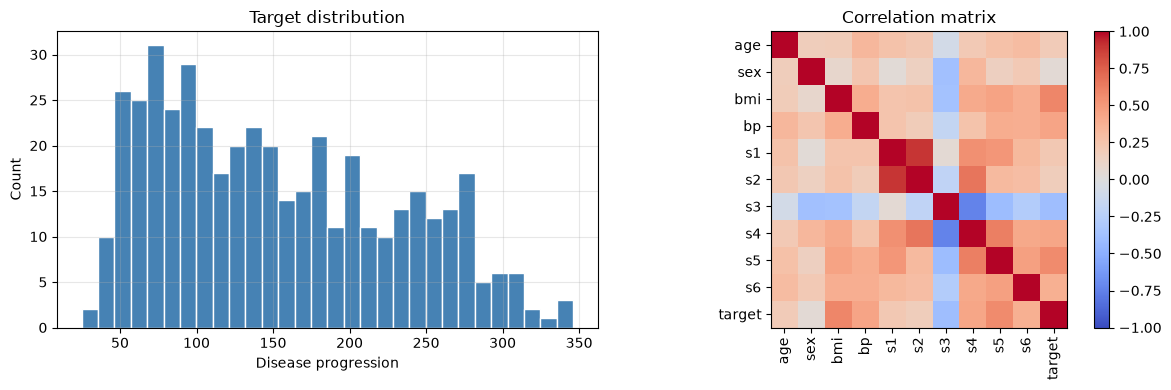

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="Target distribution", xlabel="Disease progression", ylabel="Count")
corr = df.corr()
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr))); axes[1].set_xticklabels(corr.columns, rotation=90)
axes[1].set_yticks(range(len(corr))); axes[1].set_yticklabels(corr.columns)
axes[1].grid(False); axes[1].set_title("Correlation matrix")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()
print(corr["target"].drop("target").sort_values(ascending=False).round(3))

**Observations.** The data has 442 patients and 10 features. The target (disease progression) goes from 25 to 346, and the average is about 152. The features most linked to the target are `bmi` (0.59), `s5` (0.57) and `bp` (0.44). `s3` is the only clear negative one (-0.40). Some features are also close to each other (for example `s1` and `s2` in the heatmap). This matters later for Ridge and Lasso. I split the data 80/20 with a fixed seed (42), so all models are tested on the same 89 patients.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print(X_train.shape, X_test.shape)

results = []
def evaluate(name, model, Xtr, Xte):
    ptr, pte = model.predict(Xtr), model.predict(Xte)
    row = {"Model": name,
           "Train R2": r2_score(y_train, ptr),
           "Test MAE": mean_absolute_error(y_test, pte),
           "Test MSE": mean_squared_error(y_test, pte),
           "Test RMSE": np.sqrt(mean_squared_error(y_test, pte)),
           "Test R2": r2_score(y_test, pte)}
    results.append(row)
    return pd.Series(row).drop("Model"), pte

(353, 10) (89, 10)


## Step 2: Simple linear regression

In [5]:
feat = "bmi"   # strongest single correlation with the target
slr = LinearRegression().fit(X_train[[feat]], y_train)
m, pred_slr = evaluate("Simple Linear (bmi)", slr, X_train[[feat]], X_test[[feat]])
print(f"slope={slr.coef_[0]:.1f}, intercept={slr.intercept_:.1f}")
m.round(3)

slope=998.6, intercept=152.0


Train R2        0.366
Test MAE        52.26
Test MSE     4061.826
Test RMSE      63.732
Test R2         0.233
dtype: object

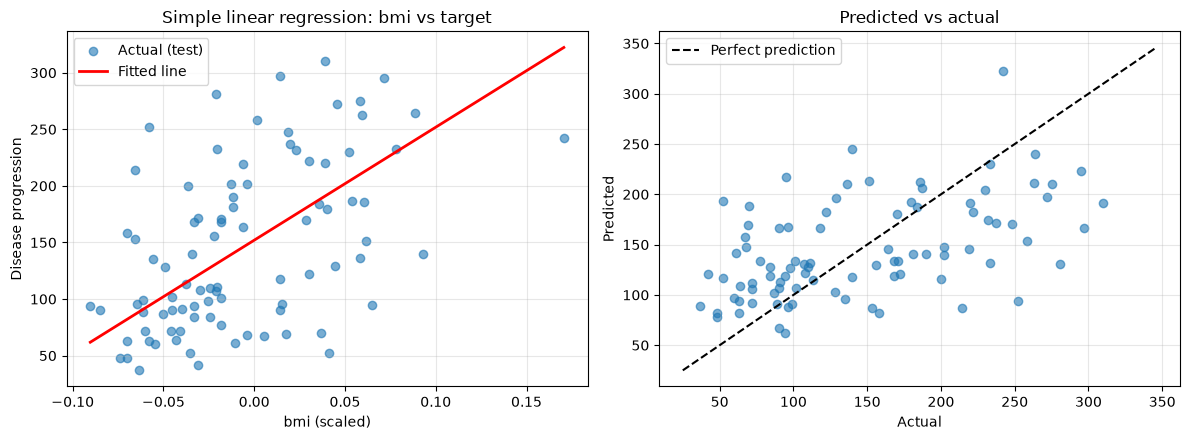

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xs = np.linspace(X[feat].min(), X[feat].max(), 100).reshape(-1, 1)
axes[0].scatter(X_test[feat], y_test, alpha=0.6, label="Actual (test)")
axes[0].plot(xs, slr.predict(pd.DataFrame(xs, columns=[feat])), "r", lw=2, label="Fitted line")
axes[0].set(title="Simple linear regression: bmi vs target", xlabel="bmi (scaled)", ylabel="Disease progression"); axes[0].legend()
axes[1].scatter(y_test, pred_slr, alpha=0.6)
lim = [y.min(), y.max()]; axes[1].plot(lim, lim, "k--", label="Perfect prediction")
axes[1].set(title="Predicted vs actual", xlabel="Actual", ylabel="Predicted"); axes[1].legend()
plt.tight_layout(); plt.show()

**Result.** Using only `bmi`, the test R² is 0.233 and the RMSE is 63.7. One feature explains only about a quarter of the target, and the dots in the plot are far from the line. This model is too simple, so it underfits.

## Step 3: Multiple regression

In [7]:
mlr = LinearRegression().fit(X_train, y_train)
m, pred_mlr = evaluate("Multiple Linear (all 10)", mlr, X_train, X_test)
display(m.round(3))
display(pd.Series(mlr.coef_, index=X.columns).round(1).rename("coefficient").to_frame().T)

Train R2        0.528
Test MAE       42.794
Test MSE     2900.194
Test RMSE      53.853
Test R2         0.453
dtype: object

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
coefficient,37.9,-242.0,542.4,347.7,-931.5,518.1,163.4,275.3,736.2,48.7


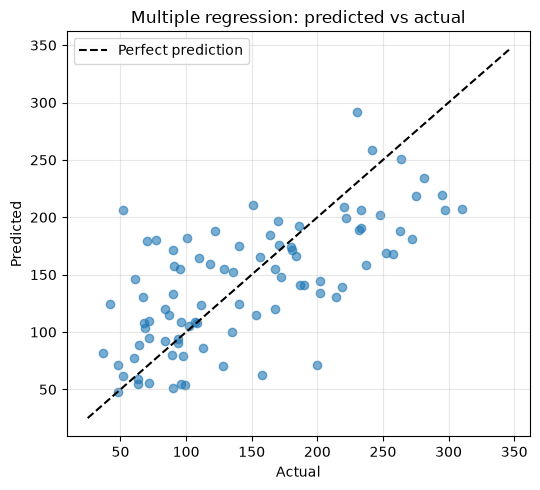

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, pred_mlr, alpha=0.6)
ax.plot(lim, lim, "k--", label="Perfect prediction")
ax.set(title="Multiple regression: predicted vs actual", xlabel="Actual", ylabel="Predicted"); ax.legend()
plt.tight_layout(); plt.show()

**Result.** Using all 10 features, the test R² goes up from 0.233 to 0.453, and the RMSE goes down from 63.7 to 53.9. So the other features really help. But the coefficients look strange: `s1` is -931 and `s2` is +518. These two features are very similar, so the model gives them big weights in opposite directions. This is not stable. Regularization should help with this.

## Step 4: Polynomial regression

In [9]:
# Degree sweep on all 10 features
rows = []
for d in range(1, 6):
    pm = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(X_train, y_train)
    rows.append({"degree": d, "n_features": pm[0].n_output_features_,
                 "Train R2": r2_score(y_train, pm.predict(X_train)),
                 "Test R2": r2_score(y_test, pm.predict(X_test)),
                 "Test RMSE": np.sqrt(mean_squared_error(y_test, pm.predict(X_test)))})
poly_df = pd.DataFrame(rows).round(3)
poly_df

,degree,n_features,Train R2,Test R2,Test RMSE
0,1,10,0.528,0.453,53.853
1,2,65,0.606,0.416,55.642
2,3,285,0.857,-5.212,181.417
3,4,1000,1.000,-26.728,383.285
4,5,3002,1.000,-25.993,378.170


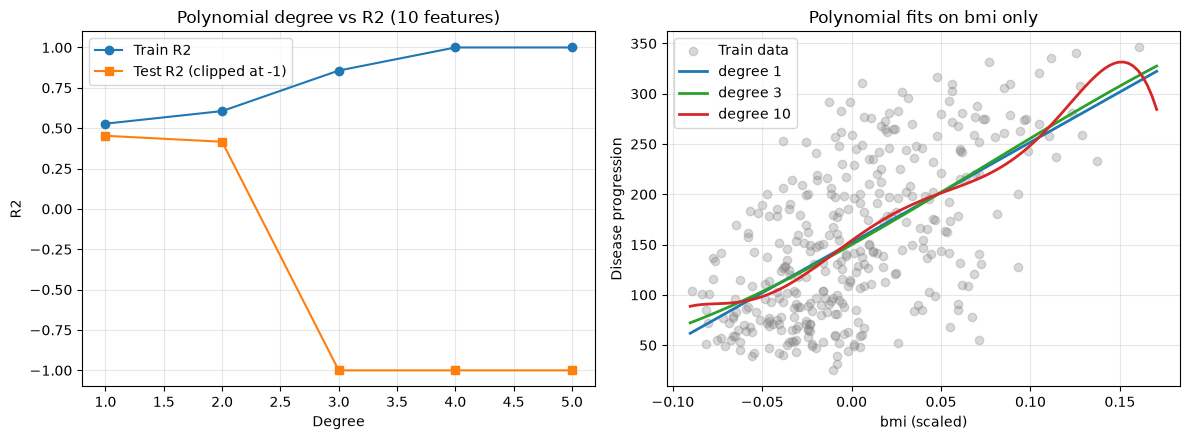

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(poly_df["degree"], poly_df["Train R2"].clip(lower=-1), "o-", label="Train R2")
axes[0].plot(poly_df["degree"], poly_df["Test R2"].clip(lower=-1), "s-", label="Test R2 (clipped at -1)")
axes[0].set(title="Polynomial degree vs R2 (10 features)", xlabel="Degree", ylabel="R2"); axes[0].legend()

xs_df = pd.DataFrame(xs, columns=[feat])
axes[1].scatter(X_train[feat], y_train, alpha=0.3, color="gray", label="Train data")
for d, c in [(1, "tab:blue"), (3, "tab:green"), (10, "tab:red")]:
    pm = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(X_train[[feat]], y_train)
    axes[1].plot(xs, pm.predict(xs_df), color=c, lw=2, label=f"degree {d}")
axes[1].set(title="Polynomial fits on bmi only", xlabel="bmi (scaled)", ylabel="Disease progression"); axes[1].legend()
plt.tight_layout(); plt.show()

In [11]:
# Polynomial models carried into the comparison table
for d in (2, 3):
    pm = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression()).fit(X_train, y_train)
    m, _ = evaluate(f"Polynomial (deg {d}, all 10)", pm, X_train, X_test)
pd.DataFrame(results).set_index("Model").tail(2).round(3)

,Train R2,Test MAE,Test MSE,Test RMSE,Test R2
Model,,,,,
"Polynomial (deg 2, all 10)",0.606,43.582,3096.028,55.642,0.416
"Polynomial (deg 3, all 10)",0.857,121.977,32911.961,181.417,-5.212


**Result.** Degree 2 has a higher train R² (0.606) but a lower test R² (0.416) than the plain linear model (0.453). So it already starts to overfit. At degree 3, the train R² is 0.857 but the test R² is -5.2, which is worse than just guessing the average. At degrees 4 and 5, there are 1000 and 3002 features but only 353 training rows. The model learns the training data perfectly (R² = 1.0) and fails on new data.

- **Underfitting:** degree 1 with `bmi` only (the straight line in the right plot). The model is too simple.
- **Good fit:** a low degree with all features.
- **Overfitting:** degree 3 and higher. Train score is high but test score is very low. The degree-10 line in the right plot swings up and down a lot, which shows the same problem.

Curved terms did not help on this data. The link between the features and the target looks mostly straight, and with only a few rows, extra terms just add noise.

## Step 5: Ridge and Lasso regression

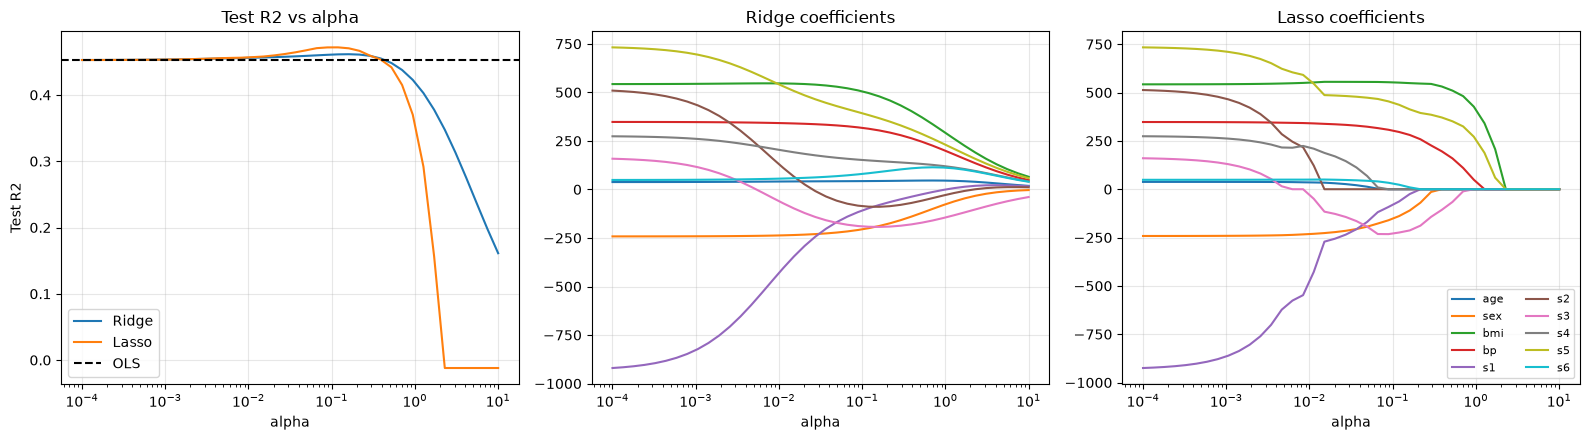

In [12]:
alphas = np.logspace(-4, 1, 40)
ridge_r2, lasso_r2, ridge_coefs, lasso_coefs = [], [], [], []
for a in alphas:
    r = Ridge(alpha=a).fit(X_train, y_train)
    l = Lasso(alpha=a, max_iter=100000).fit(X_train, y_train)
    ridge_r2.append(r2_score(y_test, r.predict(X_test))); lasso_r2.append(r2_score(y_test, l.predict(X_test)))
    ridge_coefs.append(r.coef_); lasso_coefs.append(l.coef_)
ridge_coefs, lasso_coefs = np.array(ridge_coefs), np.array(lasso_coefs)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].semilogx(alphas, ridge_r2, label="Ridge"); axes[0].semilogx(alphas, lasso_r2, label="Lasso")
axes[0].axhline(r2_score(y_test, pred_mlr), color="k", ls="--", label="OLS")
axes[0].set(title="Test R2 vs alpha", xlabel="alpha", ylabel="Test R2"); axes[0].legend()
for i, c in enumerate(X.columns):
    axes[1].semilogx(alphas, ridge_coefs[:, i], label=c)
    axes[2].semilogx(alphas, lasso_coefs[:, i], label=c)
axes[1].set(title="Ridge coefficients", xlabel="alpha"); axes[2].set(title="Lasso coefficients", xlabel="alpha")
axes[2].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
# Choose alpha by 5-fold cross-validation on the training set only
ridge_cv = RidgeCV(alphas=alphas, cv=5).fit(X_train, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=100000, random_state=RS).fit(X_train, y_train)
print(f"Best Ridge alpha: {ridge_cv.alpha_:.4f} | Best Lasso alpha: {lasso_cv.alpha_:.4f}")

ridge = Ridge(alpha=ridge_cv.alpha_).fit(X_train, y_train)
lasso = Lasso(alpha=lasso_cv.alpha_, max_iter=100000).fit(X_train, y_train)
_, pred_ridge = evaluate(f"Ridge (alpha={ridge_cv.alpha_:.3g})", ridge, X_train, X_test)
_, pred_lasso = evaluate(f"Lasso (alpha={lasso_cv.alpha_:.3g})", lasso, X_train, X_test)

# Regularize the degree-3 polynomial too, where regularization matters most
for name, est in [("Poly deg 3 + Ridge", Ridge(alpha=100)), ("Poly deg 3 + Lasso", Lasso(alpha=1.0, max_iter=200000))]:
    pm = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), est).fit(X_train, y_train)
    evaluate(name, pm, X_train, X_test)

print("Lasso zeroed:", list(X.columns[lasso.coef_ == 0]))
pd.DataFrame({"OLS": mlr.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=X.columns).round(1)

Best Ridge alpha: 0.0889 | Best Lasso alpha: 0.0661
Lasso zeroed: ['s2']


,OLS,Ridge,Lasso
age,37.9,42.7,2.6
sex,-242.0,-209.0,-177.5
bmi,542.4,510.2,554.7
bp,347.7,319.7,316.1
s1,-931.5,-116.8,-118.6
s2,518.1,-83.6,-0.0
s3,163.4,-188.5,-231.8
s4,275.3,153.4,9.4
s5,736.2,398.4,466.9
s6,48.7,77.7,40.4


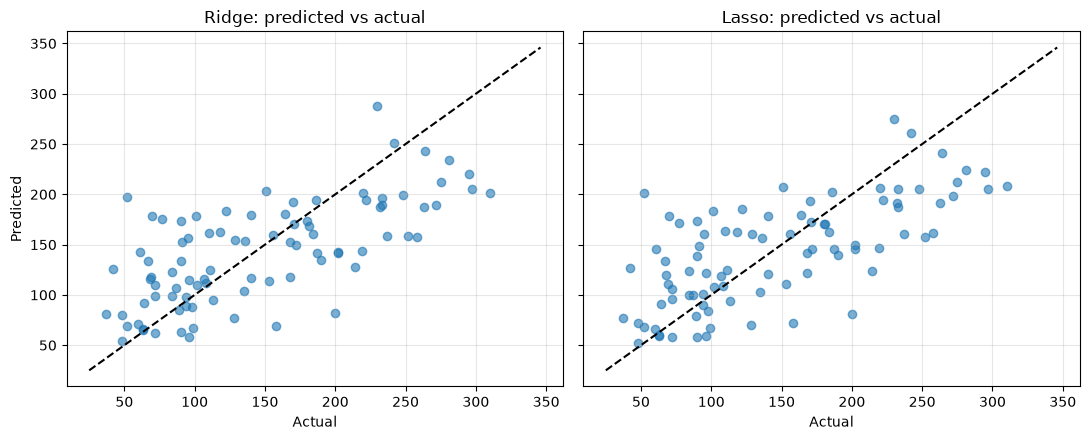

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, p, t in [(axes[0], pred_ridge, "Ridge"), (axes[1], pred_lasso, "Lasso")]:
    ax.scatter(y_test, p, alpha=0.6); ax.plot(lim, lim, "k--")
    ax.set(title=f"{t}: predicted vs actual", xlabel="Actual")
axes[0].set_ylabel("Predicted"); plt.tight_layout(); plt.show()

**How alpha works.** Alpha is the strength of the penalty. When alpha is close to 0, Ridge and Lasso give the same result as plain linear regression. When alpha gets bigger, the coefficients get smaller. Ridge makes all coefficients smaller but almost never makes them exactly zero. Lasso can make some coefficients exactly zero, so it also picks features. If alpha is too big, both models become too simple and the score drops (see the left plot).

**Result.** I chose alpha using 5-fold cross-validation on the training data only. Ridge (alpha = 0.089) gave a test R² of 0.461 and Lasso (alpha = 0.066) gave 0.471. Both are a little better than plain linear regression (0.453). In the coefficient table, Ridge reduced `s1` from -931 to -117 and `s2` from +518 to -84, so the strange pair is fixed. Lasso set `s2` to exactly 0 and made `age` and `s4` almost 0. Lasso kept the big features (`bmi`, `s5`, `bp`) close to their original size.

**Ridge vs Lasso.** Their predictions are almost the same (RMSE 53.5 vs 53.0). The difference is in the coefficients, not in the accuracy. Ridge keeps all features with smaller weights. Lasso gives a simpler model. Regularization helped most on the degree-3 polynomial: R² went from -5.2 to 0.42 (Ridge) and 0.48 (Lasso). So the penalty saved a model that was not usable. I picked those alphas by hand and not with cross-validation, so please see this as a rough example.

## Step 6: Model comparison and analysis

In [15]:
res = pd.DataFrame(results).set_index("Model").round(3)
res

,Train R2,Test MAE,Test MSE,Test RMSE,Test R2
Model,,,,,
Simple Linear (bmi),0.366,52.260,4061.826,63.732,0.233
Multiple Linear (all 10),0.528,42.794,2900.194,53.853,0.453
"Polynomial (deg 2, all 10)",0.606,43.582,3096.028,55.642,0.416
"Polynomial (deg 3, all 10)",0.857,121.977,32911.961,181.417,-5.212
Ridge (alpha=0.0889),0.521,42.976,2858.022,53.460,0.461
Lasso (alpha=0.0661),0.520,42.773,2804.851,52.961,0.471
Poly deg 3 + Ridge,0.644,45.767,3089.722,55.585,0.417
Poly deg 3 + Lasso,0.632,43.232,2757.189,52.509,0.480


In [16]:
# 5-fold CV R2 on the full dataset: more stable than a single split
cv_models = {"Simple Linear (bmi)": (LinearRegression(), [feat]),
             "Multiple Linear": (LinearRegression(), list(X.columns)),
             "Polynomial deg 2": (make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression()), list(X.columns)),
             "Polynomial deg 3": (make_pipeline(PolynomialFeatures(3, include_bias=False), LinearRegression()), list(X.columns)),
             "Ridge": (Ridge(alpha=ridge_cv.alpha_), list(X.columns)),
             "Lasso": (Lasso(alpha=lasso_cv.alpha_, max_iter=100000), list(X.columns))}
cv_tbl = pd.DataFrame({k: cross_val_score(m, X[c], y, cv=5, scoring="r2") for k, (m, c) in cv_models.items()}).agg(["mean", "std"]).T.round(3)
cv_tbl.columns = ["CV R2 mean", "CV R2 std"]
cv_tbl

,CV R2 mean,CV R2 std
Simple Linear (bmi),0.324,0.075
Multiple Linear,0.482,0.055
Polynomial deg 2,0.392,0.135
Polynomial deg 3,-21.953,31.139
Ridge,0.480,0.053
Lasso,0.482,0.053


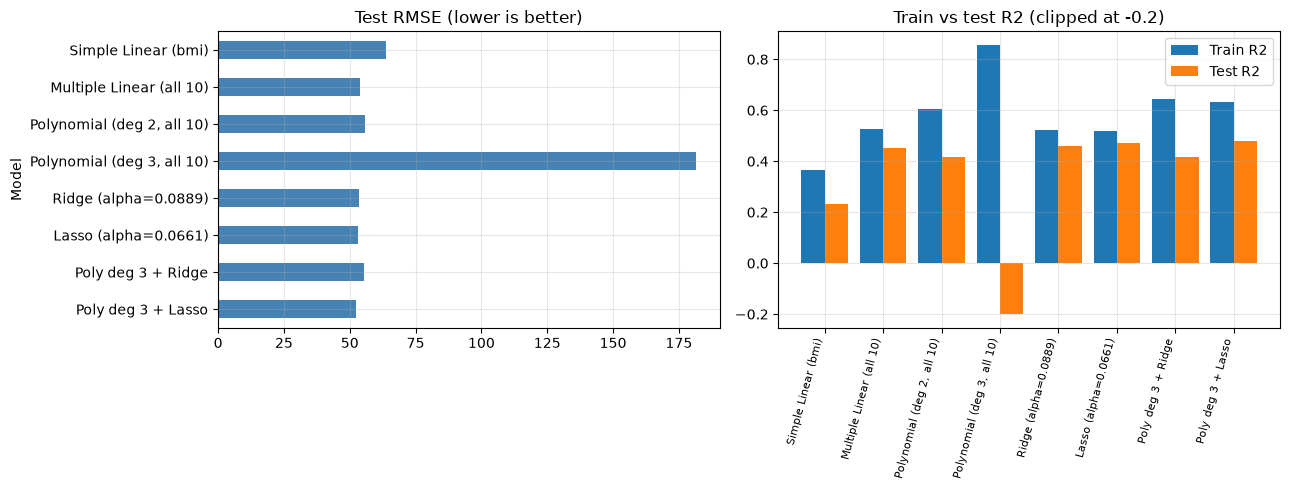

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
res["Test RMSE"].plot.barh(ax=axes[0], color="steelblue"); axes[0].set(title="Test RMSE (lower is better)"); axes[0].invert_yaxis()
x = np.arange(len(res)); axes[1].bar(x - 0.2, res["Train R2"].clip(lower=-0.2), 0.4, label="Train R2")
axes[1].bar(x + 0.2, res["Test R2"].clip(lower=-0.2), 0.4, label="Test R2")
axes[1].set_xticks(x); axes[1].set_xticklabels(res.index, rotation=75, ha="right", fontsize=8)
axes[1].set(title="Train vs test R2 (clipped at -0.2)"); axes[1].legend()
plt.tight_layout(); plt.show()

**How well each model did.** All good models are only okay. The best test R² is about 0.47 to 0.48, so about half of the target is still not explained by these 10 features. The typical error is about 43 points (MAE), and the target has a standard deviation of 77.

| Model | Test R² | Test RMSE | Comment |
|---|---|---|---|
| Simple linear (bmi) | 0.233 | 63.7 | Too simple |
| Multiple linear | 0.453 | 53.9 | Big gain from using all features |
| Polynomial deg 2 | 0.416 | 55.6 | Starts to overfit |
| Polynomial deg 3 | -5.212 | 181.4 | Very bad overfit |
| Ridge | 0.461 | 53.5 | More stable coefficients |
| Lasso | 0.471 | 53.0 | Best simple model, drops `s2` |

**Overfitting and improvement.** Overfitting means a high train R² and a low or negative test R². This happened with polynomial degree 3 and higher. Ridge and Lasso fix the unstable coefficients and give a small gain. The cross-validation table says the same: Multiple (0.482), Ridge (0.480) and Lasso (0.482) are almost equal, and degree 3 is very bad (-22). So the gain of Ridge and Lasso over plain linear regression (about 0.01 to 0.02 R²) is too small to be sure about. The honest conclusion is that regularization gives a simpler and more stable model, but not a clearly more accurate one. 'Poly deg 3 + Lasso' scored 0.480 on the test split, but this is also within the noise and it uses 285 features, so I would not choose it over plain Lasso.

**What I learned about the dataset.** The most important features are `bmi`, `s5` and `bp`, and Ridge and Lasso both keep them as the biggest coefficients. `s1` and `s2` carry almost the same information, so Lasso can drop `s2` without losing much accuracy. The data is small (442 rows) and mostly straight-line, which is why simple models win and complex models fail. Also, one train/test split with 89 rows is noisy, so I used cross-validation too, and differences smaller than about 0.02 R² should not be trusted.